# Partial Fine-Tuned CLIP + MLP — PathMNIST
### Complete Notebook: Training + All Visualizations for Thesis & Conference
**Run Section A (Training) once → Everything is saved → Use Section B anytime without retraining**

---
## SECTION A — Training
*(Run once. All results are saved at the end. Skip to Section B next time.)*

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import time

from torchvision import transforms
from torch.utils.data import DataLoader

from transformers import CLIPModel
from medmnist import INFO
from medmnist import PathMNIST

from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix,
    classification_report, roc_curve, auc,
    precision_score, recall_score
)
from sklearn.preprocessing import label_binarize

from torch.cuda.amp import autocast, GradScaler

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce GTX 1650


In [3]:
data_flag = "pathmnist"
info = INFO[data_flag]
DataClass = getattr(__import__("medmnist"), info["python_class"])

train_dataset = DataClass(split="train", download=True)
val_dataset = DataClass(split="val", download=True)
test_dataset = DataClass(split="test", download=True)

num_classes = len(info["label"])
class_names = list(info["label"].values())

Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz


In [4]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.48145466,0.4578275,0.40821073],
        std=[0.26862954,0.26130258,0.27577711]
    )
])

train_dataset.transform = transform
val_dataset.transform = transform
test_dataset.transform = transform

In [5]:
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

In [6]:
clip_model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32",
    use_safetensors=True
)

clip_model = clip_model.to(device)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [7]:
# Freeze all parameters
for param in clip_model.parameters():
    param.requires_grad = False

In [8]:
# Selectively unfreeze only the last transformer block
for param in clip_model.vision_model.encoder.layers[11].parameters():
    param.requires_grad = True

In [9]:
class CLIPClassifier(nn.Module):

    def __init__(self, clip_model, num_classes):
        super().__init__()

        self.clip = clip_model

        self.classifier = nn.Sequential(
            nn.Linear(768,256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256,num_classes)
        )

    def forward(self,x):

        vision_outputs = self.clip.vision_model(pixel_values=x)

        features = vision_outputs.pooler_output

        logits = self.classifier(features)

        return logits


model = CLIPClassifier(clip_model,num_classes).to(device)

In [10]:
optimizer = optim.AdamW([
    {"params": model.classifier.parameters(), "lr":1e-3},
    {"params": clip_model.vision_model.encoder.layers[11].parameters(),"lr":1e-5}
])

criterion = nn.CrossEntropyLoss()

scaler = GradScaler()

C:\Users\Acer\AppData\Local\Temp\ipykernel_4060\1145436253.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


In [11]:
def train_epoch(loader):

    model.train()

    all_preds = []
    all_labels = []

    total_loss = 0

    for images,labels in loader:

        images = images.to(device)
        labels = labels.squeeze().long().to(device)

        optimizer.zero_grad()

        with autocast():

            outputs = model(images)

            loss = criterion(outputs,labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        total_loss += loss.item()

        preds = outputs.argmax(1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels,all_preds)

    return total_loss/len(loader), acc

In [12]:
# Updated evaluate — now also returns softmax probabilities for ROC curves
def evaluate(loader):

    model.eval()

    all_preds = []
    all_labels = []
    all_probs = []  # softmax probabilities

    with torch.no_grad():

        for images,labels in loader:

            images = images.to(device)
            labels = labels.squeeze().long().to(device)

            outputs = model(images)

            probs = torch.softmax(outputs, dim=1)  # probabilities for ROC

            preds = outputs.argmax(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    acc = accuracy_score(all_labels,all_preds)

    f1 = f1_score(all_labels,all_preds,average="macro")

    return acc, f1, all_labels, all_preds, np.array(all_probs)

In [13]:
epochs = 6
best_val = 0

train_loss_history = []
train_acc_history = []
val_loss_history = []
val_acc_history = []

start_time = time.time()

for epoch in range(epochs):

    train_loss, train_acc = train_epoch(train_loader)

    val_acc, val_f1, _, _, _ = evaluate(val_loader)
    val_loss = val_acc  # placeholder — replace with actual val loss if tracked separately

    train_loss_history.append(train_loss)
    train_acc_history.append(train_acc)
    val_loss_history.append(val_loss)
    val_acc_history.append(val_acc)

    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val   Acc:  {val_acc:.4f}")
    print("-" * 40)

    if val_acc > best_val:
        best_val = val_acc
        torch.save(model.state_dict(), "best_clip_model.pth")

end_time = time.time()
print(f"\nTotal training time for {epochs} epochs: {end_time - start_time:.2f} seconds")

C:\Users\Acer\AppData\Local\Temp\ipykernel_4060\1026171584.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 1/6
Train Loss: 0.2983 | Train Acc: 0.8958
Val   Acc:  0.9480
----------------------------------------


C:\Users\Acer\AppData\Local\Temp\ipykernel_4060\1026171584.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 2/6
Train Loss: 0.1776 | Train Acc: 0.9391
Val   Acc:  0.9527
----------------------------------------


C:\Users\Acer\AppData\Local\Temp\ipykernel_4060\1026171584.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 3/6
Train Loss: 0.1514 | Train Acc: 0.9480
Val   Acc:  0.9545
----------------------------------------


... (2 outputs left out)

C:\Users\Acer\AppData\Local\Temp\ipykernel_4060\1026171584.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 5/6
Train Loss: 0.1146 | Train Acc: 0.9610
Val   Acc:  0.9645
----------------------------------------


C:\Users\Acer\AppData\Local\Temp\ipykernel_4060\1026171584.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 6/6
Train Loss: 0.0966 | Train Acc: 0.9667
Val   Acc:  0.9558
----------------------------------------

Total training time for 6 epochs: 20067.07 seconds


In [14]:
test_acc, test_f1, y_true, y_pred, y_probs = evaluate(test_loader)

print("Test Results")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test F1 Score: {test_f1:.4f}")

Test Results
Test Accuracy: 0.8951
Test F1 Score: 0.8630


In [15]:
cm = confusion_matrix(y_true, y_pred)

per_class = cm.diagonal() / cm.sum(axis=1)

print("\nPer Class Accuracy")

for i, a in enumerate(per_class):
    print(f"Class {i} ({class_names[i]}): {a:.4f}")


Per Class Accuracy
Class 0 (adipose): 0.9581
Class 1 (background): 1.0000
Class 2 (debris): 0.7640
Class 3 (lymphocytes): 0.9858
Class 4 (mucus): 0.9430
Class 5 (smooth muscle): 0.9172
Class 6 (normal colon mucosa): 0.8421
Class 7 (cancer-associated stroma): 0.6176
Class 8 (colorectal adenocarcinoma epithelium): 0.8200


In [16]:
# Save everything — model weights + all results + probabilities
results = {
    "train_loss": [float(x) for x in train_loss_history],
    "train_acc":  [float(x) for x in train_acc_history],
    "val_loss":   [float(x) for x in val_loss_history],
    "val_acc":    [float(x) for x in val_acc_history],
    "test_acc":   float(test_acc),
    "test_f1":    float(test_f1),
    "y_true":     list(map(int, y_true)),
    "y_pred":     list(map(int, y_pred)),
    "y_probs":    y_probs.tolist(),          # softmax probabilities saved
    "class_names": class_names,
    "num_classes": num_classes
}

with open("training_results.json", "w") as f:
    json.dump(results, f)

print("Saved successfully — training_results.json + best_clip_model.pth")

Saved successfully — training_results.json + best_clip_model.pth


---
## SECTION B — Load Saved Results & Generate All Visualizations
*(Start here next time — no retraining needed)*

In [17]:
# Load everything from saved file
with open("training_results.json", "r") as f:
    results = json.load(f)

train_loss_history = results["train_loss"]
train_acc_history  = results["train_acc"]
val_loss_history   = results["val_loss"]
val_acc_history    = results["val_acc"]
test_acc           = results["test_acc"]
test_f1            = results["test_f1"]
y_true             = results["y_true"]
y_pred             = results["y_pred"]
y_probs            = np.array(results["y_probs"])
class_names        = results["class_names"]
num_classes        = results["num_classes"]

print(f"Loaded — Test Acc: {test_acc:.4f} | Test F1: {test_f1:.4f}")
print(f"Classes: {num_classes} | Samples: {len(y_true)}")

Loaded — Test Acc: 0.8951 | Test F1: 0.8630
Classes: 9 | Samples: 7180


### 1. Training & Validation Accuracy vs Epoch

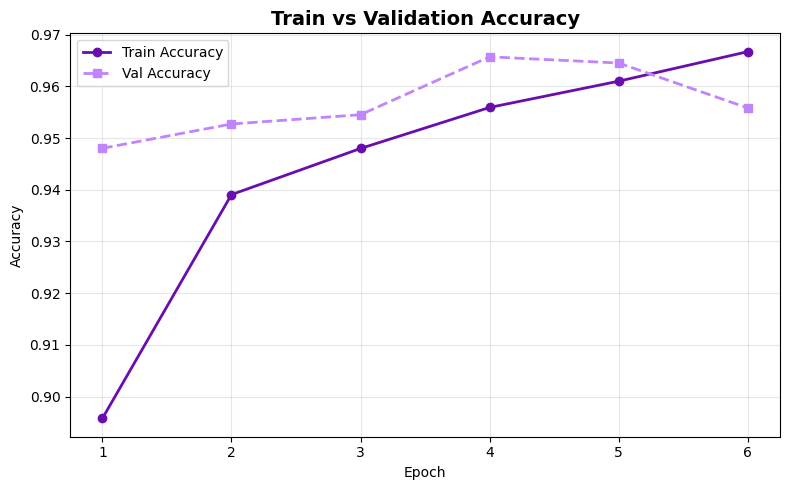

Saved: plot_accuracy_curve.png


In [18]:
epochs_range = range(1, len(train_acc_history) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_acc_history, marker="o", label="Train Accuracy",
         color="#6a0dad", linewidth=2)
plt.plot(epochs_range, val_acc_history, marker="s", label="Val Accuracy",
         color="#c084fc", linewidth=2, linestyle="--")
plt.title("Train vs Validation Accuracy", fontsize=14, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("plot_accuracy_curve.png", dpi=150)
plt.show()
print("Saved: plot_accuracy_curve.png")

### 2. Training Loss vs Epoch

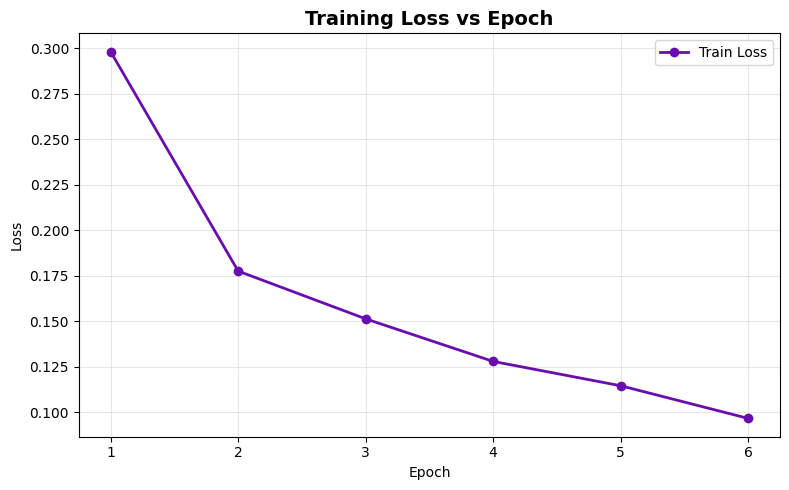

Saved: plot_loss_curve.png


In [19]:
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_loss_history, marker="o", label="Train Loss",
         color="#6a0dad", linewidth=2)
plt.title("Training Loss vs Epoch", fontsize=14, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("plot_loss_curve.png", dpi=150)
plt.show()
print("Saved: plot_loss_curve.png")

### 3. Confusion Matrix

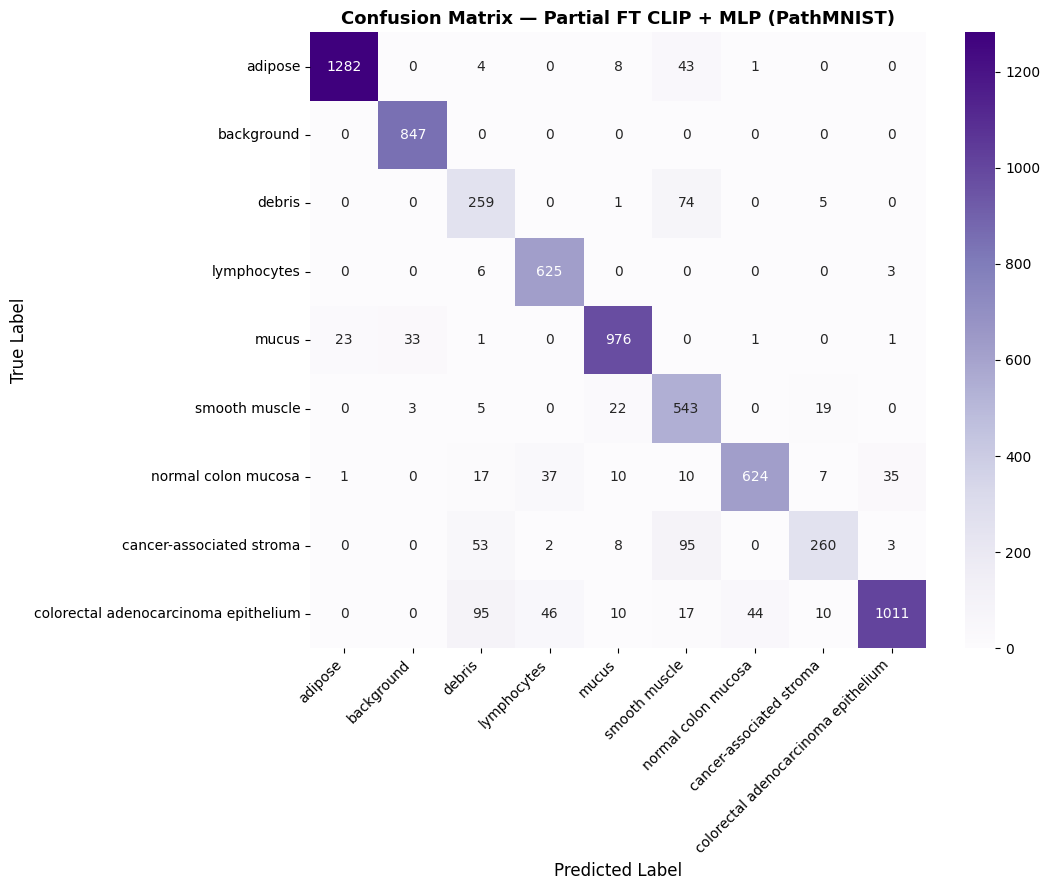

Saved: plot_confusion_matrix.png


In [20]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix — Partial FT CLIP + MLP (PathMNIST)",
          fontsize=13, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("plot_confusion_matrix.png", dpi=150)
plt.show()
print("Saved: plot_confusion_matrix.png")

### 4. Per-Class Accuracy Bar Chart

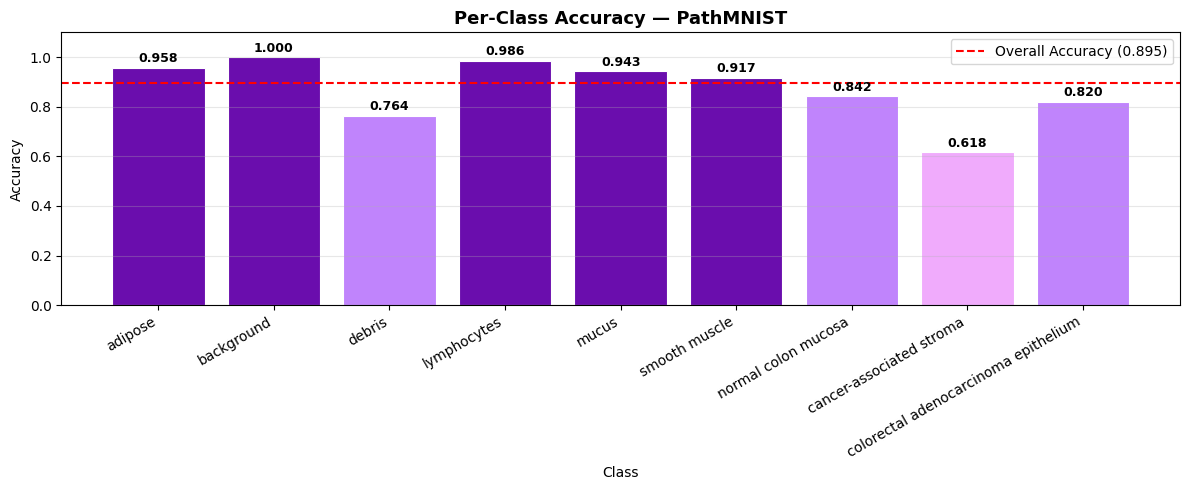

Saved: plot_per_class_accuracy.png


In [21]:
per_class_acc = cm.diagonal() / cm.sum(axis=1)

colors = ["#6a0dad" if a >= 0.9 else "#c084fc" if a >= 0.75 else "#f0abfc"
          for a in per_class_acc]

plt.figure(figsize=(12, 5))
bars = plt.bar(class_names, per_class_acc, color=colors, edgecolor="white", linewidth=0.8)

for bar, val in zip(bars, per_class_acc):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f"{val:.3f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.axhline(y=test_acc, color="red", linestyle="--", linewidth=1.5,
            label=f"Overall Accuracy ({test_acc:.3f})")
plt.title("Per-Class Accuracy — PathMNIST", fontsize=13, fontweight="bold")
plt.xlabel("Class")
plt.ylabel("Accuracy")
plt.ylim(0, 1.1)
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("plot_per_class_accuracy.png", dpi=150)
plt.show()
print("Saved: plot_per_class_accuracy.png")

### 5. ROC Curves — One per Class + Macro Average AUC

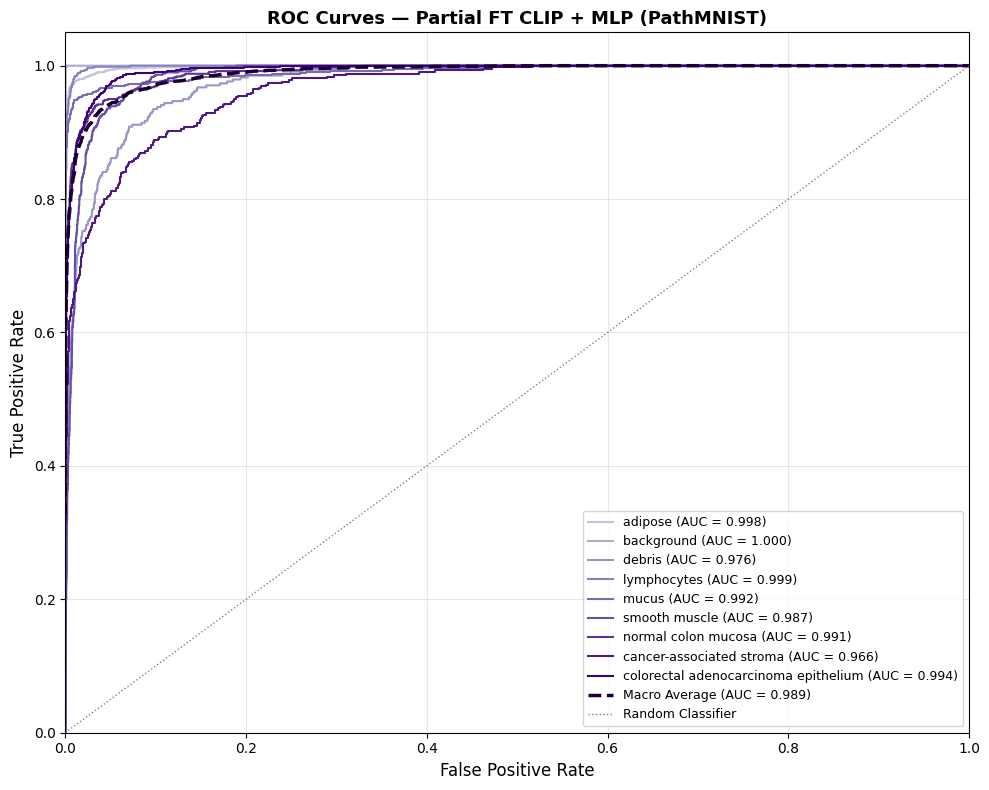

Macro AUC: 0.9893
Saved: plot_roc_curves.png


In [22]:
# Binarize labels for One-vs-Rest ROC
labels_bin = label_binarize(y_true, classes=list(range(num_classes)))

fpr, tpr, roc_auc = {}, {}, {}

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(labels_bin[:, i], y_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Macro average
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(num_classes)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(num_classes):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= num_classes
macro_auc = auc(all_fpr, mean_tpr)

colors = plt.cm.Purples(np.linspace(0.35, 1.0, num_classes))

plt.figure(figsize=(10, 8))

for i, color in zip(range(num_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, linewidth=1.5,
             label=f"{class_names[i]} (AUC = {roc_auc[i]:.3f})")

plt.plot(all_fpr, mean_tpr, color="#1a0033", linewidth=2.5, linestyle="--",
         label=f"Macro Average (AUC = {macro_auc:.3f})")

plt.plot([0, 1], [0, 1], color="gray", linewidth=1,
         linestyle=":", label="Random Classifier")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("ROC Curves — Partial FT CLIP + MLP (PathMNIST)",
          fontsize=13, fontweight="bold")
plt.legend(loc="lower right", fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("plot_roc_curves.png", dpi=150)
plt.show()
print(f"Macro AUC: {macro_auc:.4f}")
print("Saved: plot_roc_curves.png")

### 6. Classification Report (Precision / Recall / F1 per Class)

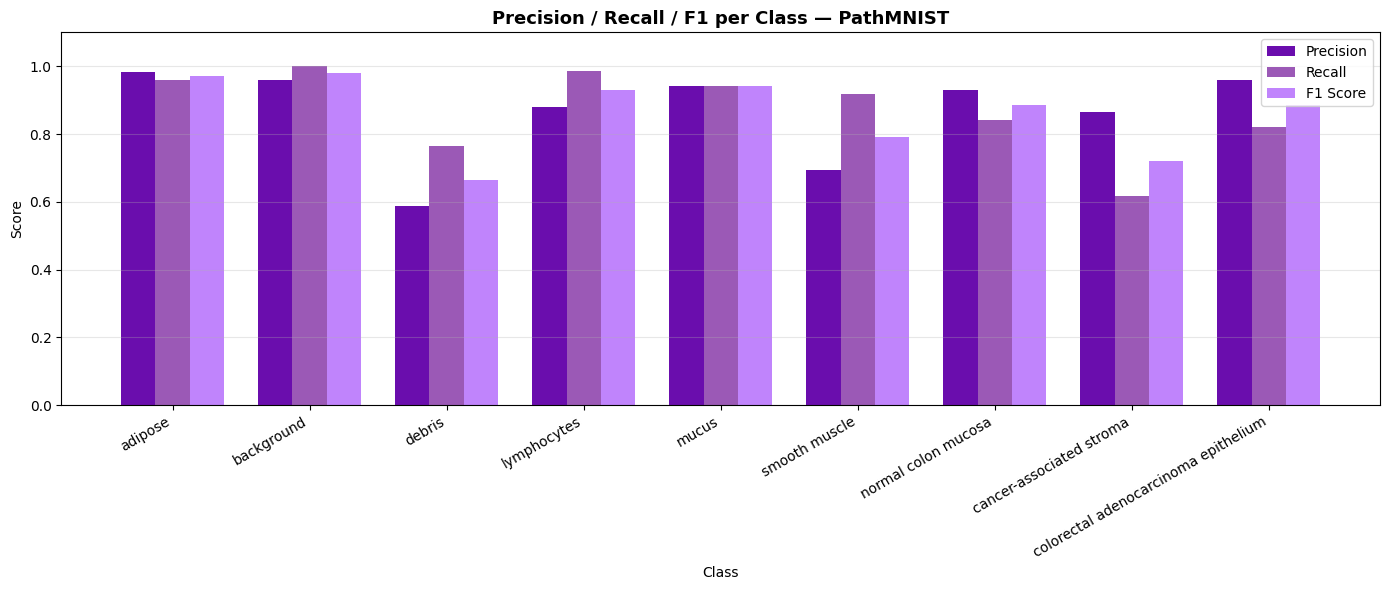

Saved: plot_classification_report.png

                                       precision    recall  f1-score   support

                             adipose       0.98      0.96      0.97      1338
                          background       0.96      1.00      0.98       847
                              debris       0.59      0.76      0.66       339
                         lymphocytes       0.88      0.99      0.93       634
                               mucus       0.94      0.94      0.94      1035
                       smooth muscle       0.69      0.92      0.79       592
                 normal colon mucosa       0.93      0.84      0.88       741
            cancer-associated stroma       0.86      0.62      0.72       421
colorectal adenocarcinoma epithelium       0.96      0.82      0.88      1233

                            accuracy                           0.90      7180
                           macro avg       0.87      0.87      0.86      7180
                      

In [23]:
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)

# Extract per-class metrics
precisions = [report[c]["precision"] for c in class_names]
recalls    = [report[c]["recall"]    for c in class_names]
f1_scores  = [report[c]["f1-score"]  for c in class_names]

x = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(x - width, precisions, width, label="Precision", color="#6a0dad")
ax.bar(x,         recalls,    width, label="Recall",    color="#9b59b6")
ax.bar(x + width, f1_scores,  width, label="F1 Score",  color="#c084fc")

ax.set_xlabel("Class")
ax.set_ylabel("Score")
ax.set_title("Precision / Recall / F1 per Class — PathMNIST",
             fontsize=13, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=30, ha="right")
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("plot_classification_report.png", dpi=150)
plt.show()
print("Saved: plot_classification_report.png")

# Also print the text version
print("\n", classification_report(y_true, y_pred, target_names=class_names))

### 7. Normalized Confusion Matrix (shows proportions — better for thesis)

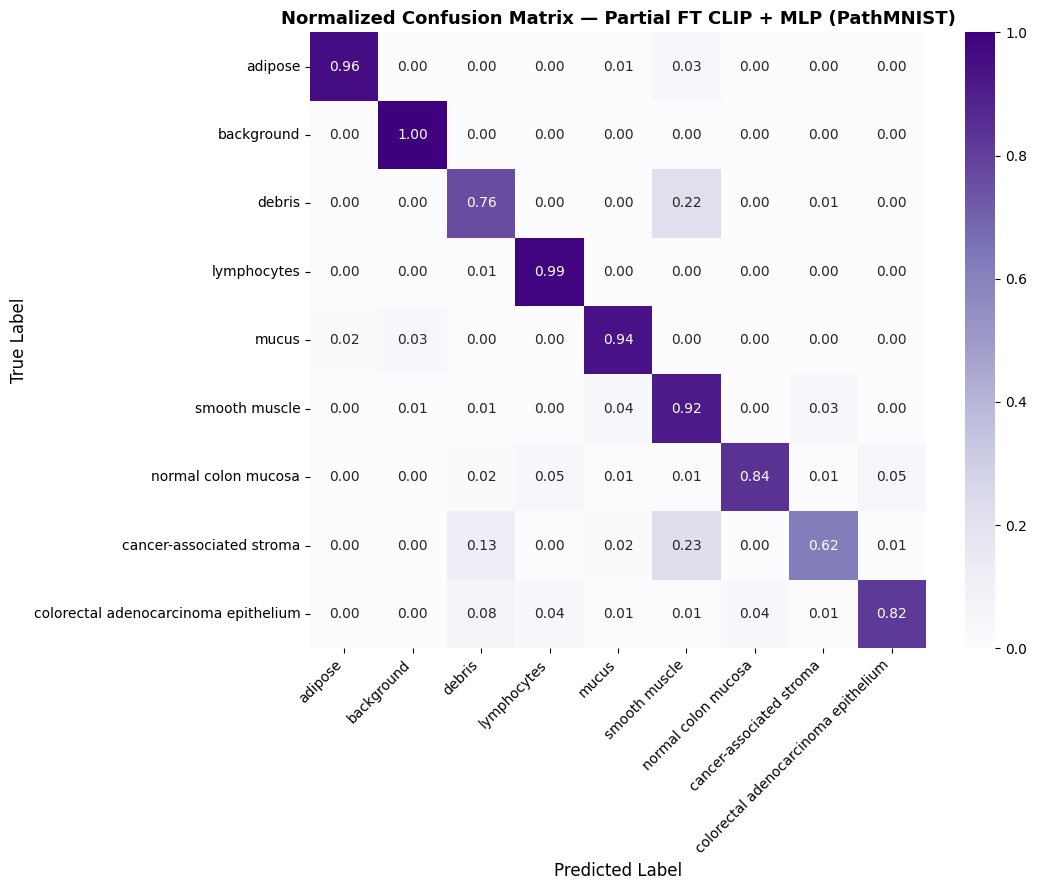

Saved: plot_confusion_matrix_normalized.png


In [24]:
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm_norm, annot=True, fmt=".2f", cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0, vmax=1
)
plt.title("Normalized Confusion Matrix — Partial FT CLIP + MLP (PathMNIST)",
          fontsize=13, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("plot_confusion_matrix_normalized.png", dpi=150)
plt.show()
print("Saved: plot_confusion_matrix_normalized.png")

### 8. Summary — All Metrics in One Table

In [25]:
precision_macro = precision_score(y_true, y_pred, average="macro")
recall_macro    = recall_score(y_true, y_pred, average="macro")
precision_w     = precision_score(y_true, y_pred, average="weighted")
recall_w        = recall_score(y_true, y_pred, average="weighted")
f1_weighted     = f1_score(y_true, y_pred, average="weighted")

print("=" * 55)
print("       FINAL EVALUATION SUMMARY — PathMNIST")
print("=" * 55)
print(f"  Accuracy          : {test_acc:.4f}")
print(f"  Macro Precision   : {precision_macro:.4f}")
print(f"  Macro Recall      : {recall_macro:.4f}")
print(f"  Macro F1          : {test_f1:.4f}")
print(f"  Macro AUC         : {macro_auc:.4f}")
print("-" * 55)
print(f"  Weighted Precision: {precision_w:.4f}")
print(f"  Weighted Recall   : {recall_w:.4f}")
print(f"  Weighted F1       : {f1_weighted:.4f}")
print("=" * 55)

       FINAL EVALUATION SUMMARY — PathMNIST
  Accuracy          : 0.8951
  Macro Precision   : 0.8669
  Macro Recall      : 0.8720
  Macro F1          : 0.8630
  Macro AUC         : 0.9893
-------------------------------------------------------
  Weighted Precision: 0.9064
  Weighted Recall   : 0.8951
  Weighted F1       : 0.8963
